# 01 · Descarga desde la API del USGS y calidad del catálogo

El cliente (`src/sismos/cliente_usgs.py`) pide **un año por consulta**, guarda cada respuesta en `data/raw/usgs/` y, si un intervalo supera el límite de 20 000 eventos, lo parte en dos. Aquí se muestra la caché (no se vuelve a consultar la API) y lo que encontró la limpieza.

In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

from sismos import config, analisis, graficos
from sismos import gutenberg_richter as gr

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
ecuador = pd.read_parquet(config.CATALOGO_ECUADOR)
mundo = pd.read_parquet(config.CATALOGO_CINTURON)
historico = pd.read_parquet(config.CATALOGO_HISTORICO)
resultados = json.loads(config.RESULTADOS.read_text(encoding="utf-8"))
print(f"Ecuador: {len(ecuador):,} sismos · mundo M≥5: {len(mundo):,} · histórico M≥6: {len(historico):,}")

Ecuador: 3,214 sismos · mundo M≥5: 87,784 · histórico M≥6: 139


In [2]:
from sismos.cliente_usgs import ClienteUSGS
from sismos.descarga import CATALOGOS, union_cruda

cliente = ClienteUSGS()
for etiqueta in CATALOGOS:
    archivos = sorted((config.CACHE_USGS / etiqueta).glob('*.csv'))
    mb = sum(a.stat().st_size for a in archivos) / 1e6
    print(f'{etiqueta:22s} {len(archivos):3d} respuestas en caché · {mb:5.1f} MB')
pd.read_csv(config.REPORTES / 'log_descarga.csv')

ecuador_m2.5            56 respuestas en caché ·   0.6 MB
mundo_m5                53 respuestas en caché ·  14.9 MB
ecuador_m6_historico     6 respuestas en caché ·   0.0 MB


,catalogo,eventos,archivo,mb,llamadas_red_esta_corrida,consultas_en_cache,fecha
0,ecuador_m2.5,3215,union_ecuador_m2.5.parquet,0.24,59,56,2026-10-22 00:50 UTC
1,mundo_m5,88359,union_mundo_m5.parquet,5.36,59,56,2026-10-22 00:50 UTC
2,ecuador_m6_historico,139,union_ecuador_m6_historico.parquet,0.03,59,56,2026-10-22 00:50 UTC


Volver a pedir un año ya descargado sale de la caché: **cero llamadas a la red**.

In [3]:
from datetime import datetime
t = cliente.consultar('ecuador_m2.5', datetime(2016, 1, 1), datetime(2017, 1, 1), config.ECUADOR, 2.5)
print(len(t), 'eventos en 2016 · llamadas a la red:', cliente.llamadas_red)

201 eventos en 2016 · llamadas a la red: 0


## Informe de calidad

Tipos de evento, duplicados, profundidades fijas y escalas de magnitud.

In [4]:
pd.DataFrame({k: {c: v for c, v in d.items() if not isinstance(v, dict)} for k, d in resultados['calidad'].items()})

,ecuador,mundo_m5,historico_m6
filas_crudas,3215.000,88359.000,139.000
duplicados_por_id,0.000,0.000,0.000
sin_magnitud,0.000,0.000,0.000
casi_duplicados,1.000,82.000,0.000
sin_profundidad,0.000,0.000,1.000
profundidad_fija,830.000,27543.000,11.000
profundidad_fija_pct,25.800,31.400,7.900
conversion_fuera_de_rango,17.000,105.000,1.000
cambio_medio_mb_a_mw,0.357,0.255,0.015
cambio_medio_ms_a_mw,0.344,0.237,0.012


In [5]:
pd.DataFrame({k: d['familias_magnitud'] for k, d in resultados['calidad'].items()}).fillna(0).astype(int)

,ecuador,mundo_m5,historico_m6
mb,2674,41179,2
Mw,380,43003,133
Local,137,337,0
Ms,21,3241,4
Desconocida,2,24,0


## Homogeneización de magnitudes

mb y Ms se convierten a Mw con Scordilis (2006). Para no crear picos falsos en el histograma, cada magnitud se reparte al azar dentro de su clase de reporte (±0,05) antes de convertir.

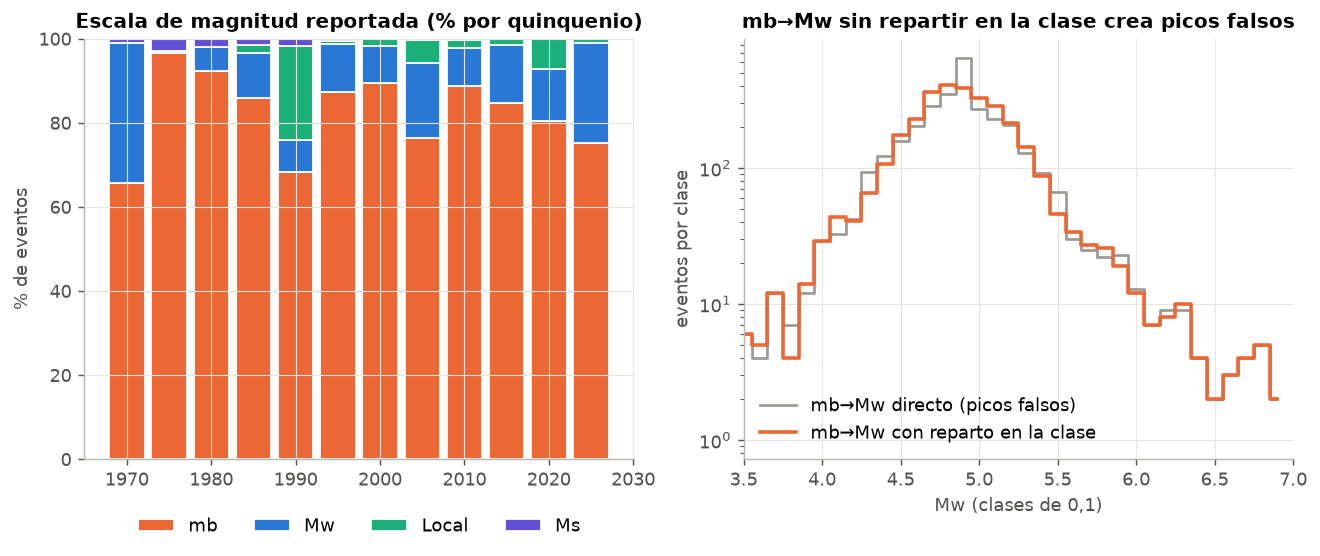

In [6]:
display(Image(config.FIGURAS / '01_calidad_magnitudes.png'))

In [7]:
ecuador.groupby('familia_mag')[['mag_original', 'mw']].describe().T.round(2)

familia_mag         Desconocida   Local     Ms      Mw       mb
mag_original count         2.00  137.00  21.00  380.00  2674.00
             mean          3.95    3.72   5.33    5.46     4.49
             std           0.07    0.57   0.97    0.64     0.36
             min           3.90    2.50   3.40    4.00     3.10
             25%           3.92    3.20   4.90    5.10     4.30
             50%           3.95    3.90   5.30    5.30     4.50
             75%           3.98    4.20   5.70    5.70     4.70
             max           4.00    4.70   7.70    8.00     6.20
mw           count         2.00  137.00  21.00  380.00  2674.00
             mean          3.95    3.72   5.68    5.46     4.85
             std           0.07    0.57   0.73    0.64     0.31
             min           3.90    2.50   4.30    4.00     3.60
             25%           3.92    3.20   5.40    5.10     4.70
             50%           3.95    3.90   5.60    5.30     4.80
             75%           3.98    4.20   5.90    5.70     5.00
             max           4.00    4.70   7.70    8.00     6.30

**Profundidad fija:** cuando el localizador no puede resolver la profundidad la fija en 10, 33 o 35 km. No se imputa: se marca y se excluye del corte de subducción.

In [8]:
ecuador.groupby('profundidad_fija')['profundidad_km'].describe()

,count,mean,std,min,25%,50%,75%,max
profundidad_fija,,,,,,,,
False,2384.0,73.117,56.813,0.0,26.6,54.35,113.015,254.0
True,830.0,28.757,9.038,10.0,33.0,33.00,33.000,35.0
